Stroke Prediction — Predictive and Prescriptive Analytics - jaybat1453 - 11/4/2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

student_id = "jaybat1453"
df = pd.read_excel(r"C:\Users\Student\Downloads\Stroke_Prediction_Excel_Analysis_jaybat1453.xlsx", sheet_name='Patient Data')
print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values by column:")
display(df.isna().sum().to_frame('Missing Values'))

Dataset shape: (15000, 34)


,Patient ID,Patient Name,Age,Gender,Hypertension,Heart Disease,Marital Status,Work Type,Residence Type,Average Glucose Level,...,Dizziness,Seizures,Weakness,Severe Fatigue,Headache,Confusion,Difficulty Speaking,Numbness,Loss of Balance,Diagnosis
0,18153,Mamooty Khurana,56,Male,0,1,Married,Self-employed,Rural,130.91,...,0,0,0,0,1,0,1,0,0,Stroke
1,62749,Kaira Subramaniam,80,Male,0,0,Single,Self-employed,Urban,183.73,...,1,0,0,0,1,1,0,0,1,Stroke
2,32145,Dhanush Balan,26,Male,1,1,Married,Never Worked,Rural,189.00,...,1,1,0,0,0,0,0,0,0,Stroke
3,6154,Ivana Baral,73,Male,0,0,Married,Never Worked,Urban,185.29,...,0,1,0,1,1,1,0,0,0,No Stroke
4,48973,Darshit Jayaraman,51,Male,1,1,Divorced,Self-employed,Urban,177.34,...,0,0,0,0,0,0,1,0,0,Stroke



Missing values by column:


,Missing Values
Patient ID,0
Patient Name,0
Age,0
Gender,0
Hypertension,0
Heart Disease,0
Marital Status,0
Work Type,0
Residence Type,0
Average Glucose Level,0


In [2]:
target_col = "Diagnosis"
y_text = df[target_col].astype(str).str.strip().str.casefold()
y = y_text.map({"stroke": 1, "no stroke": 0})
valid = y.notna()
df = df.loc[valid].copy()
y = y.loc[valid].astype(int)

drop_cols = [target_col, "Patient ID", "Patient Name", "ID"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
for c in X.select_dtypes(include='bool').columns:
    X[c] = X[c].astype(str)

categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])
print("Categorical columns encoded:", categorical_features)
print("Numeric columns:", numeric_features)

Categorical columns encoded: ['Gender', 'Marital Status', 'Work Type', 'Residence Type', 'Smoking Status', 'Alcohol Intake', 'Physical Activity', 'Family History of Stroke', 'Dietary Habits']
Numeric columns: ['Age', 'Hypertension', 'Heart Disease', 'Average Glucose Level', 'Body Mass Index (BMI)', 'Stroke History', 'Stress Levels', 'Systolic Blood Pressure', 'Diastolic Blood Pressure', 'HDL Cholesterol', 'LDL Cholesterol', 'Not Reported', 'Blurred Vision', 'Dizziness', 'Seizures', 'Weakness', 'Severe Fatigue', 'Headache', 'Confusion', 'Difficulty Speaking', 'Numbness', 'Loss of Balance']


C:\Users\Student\AppData\Local\Temp\ipykernel_9928\321206317.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])
model.fit(X_train, y_train)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 12000
Testing rows: 3000


In [4]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision: {precision:.4f} ({precision:.2%})")
print(f"Recall: {recall:.4f} ({recall:.2%})")

Accuracy: 0.5070 (50.70%)
Precision: 0.5053 (50.53%)
Recall: 0.4813 (48.13%)


,Feature,Coefficient,Absolute Importance
0,categorical__Dietary Habits_Paleo,0.052155,0.052155
1,numeric__HDL Cholesterol,-0.045950,0.045950
2,categorical__Dietary Habits_Pescatarian,-0.044484,0.044484
3,categorical__Dietary Habits_Keto,0.043128,0.043128
4,categorical__Marital Status_Married,0.042966,0.042966
5,numeric__Stress Levels,-0.037744,0.037744
6,categorical__Smoking Status_Formerly Smoked,-0.036736,0.036736
7,numeric__Average Glucose Level,0.033092,0.033092
8,categorical__Family History of Stroke_Yes,-0.032359,0.032359
9,categorical__Alcohol Intake_Rarely,0.032358,0.032358


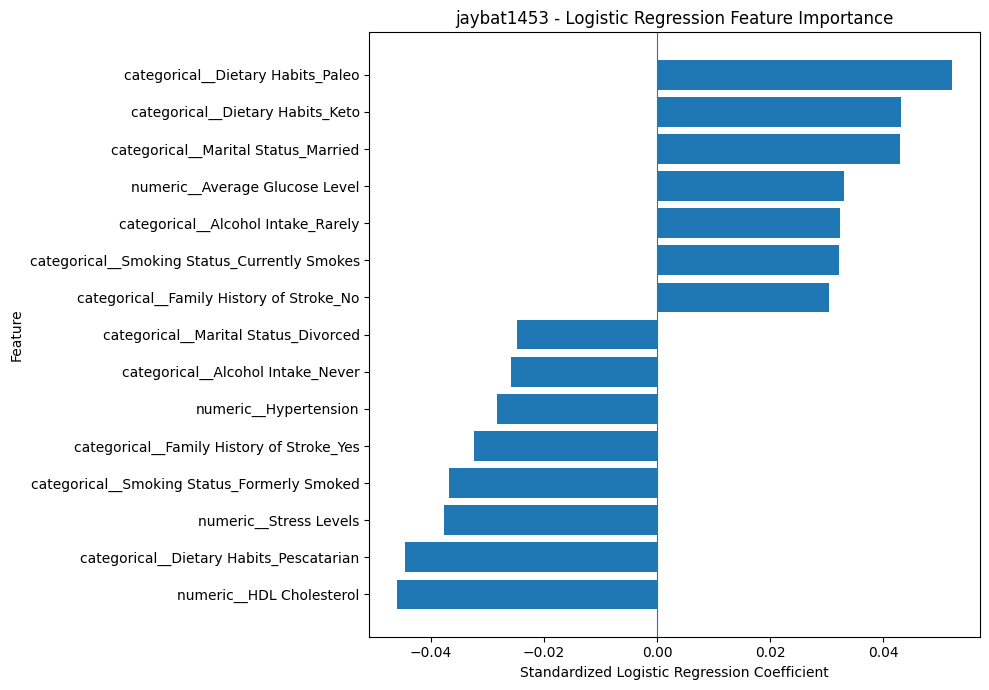

In [5]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
coefficients = model.named_steps['classifier'].coef_[0]
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Absolute Importance': np.abs(coefficients)
}).sort_values('Absolute Importance', ascending=False).reset_index(drop=True)
display(feature_importance.head(20))

top_features = feature_importance.head(15).sort_values('Coefficient')
plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Coefficient'])
plt.title(f'{student_id} - Logistic Regression Feature Importance')
plt.xlabel('Standardized Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

In [6]:
# Create a test-set scenario and select patients above the median predicted risk.
scenario = X_test.copy()
scenario['Predicted Likelihood of stroke before intervention'] = model.predict_proba(X_test)[:, 1]
median_risk = scenario['Predicted Likelihood of stroke before intervention'].median()
high_risk_mask = scenario['Predicted Likelihood of stroke before intervention'] > median_risk
intervention_group = scenario.loc[high_risk_mask].copy()

# Apply the two hypothetical changes while keeping all other features unchanged.
intervention_features = intervention_group.drop(
    columns=['Predicted Likelihood of stroke before intervention']
).copy()
intervention_features['Body Mass Index (BMI)'] = (
    intervention_features['Body Mass Index (BMI)'] * 0.90
)
intervention_features['Stress Levels'] = (
    intervention_features['Stress Levels'] * 0.95
)

# Use predict_proba for likelihoods; predict() returns only a class label.
after_probability = model.predict_proba(intervention_features)[:, 1]
intervention_group['Predicted Likelihood of stroke after intervention'] = after_probability
intervention_group['Change in Predicted Likelihood'] = (
    intervention_group['Predicted Likelihood of stroke after intervention'] -
    intervention_group['Predicted Likelihood of stroke before intervention']
)

print('Median baseline predicted likelihood:', round(median_risk, 4))
print('Patients in intervention subset:', len(intervention_group))
print('Mean likelihood before:', round(intervention_group[
    'Predicted Likelihood of stroke before intervention'].mean(), 4))
print('Mean likelihood after:', round(intervention_group[
    'Predicted Likelihood of stroke after intervention'].mean(), 4))
display(intervention_group[[
    'Predicted Likelihood of stroke before intervention',
    'Predicted Likelihood of stroke after intervention',
    'Change in Predicted Likelihood'
]].head())

Median baseline predicted likelihood: 0.4981
Patients in intervention subset: 1500
Mean likelihood before: 0.5204
Mean likelihood after: 0.5228


,Predicted Likelihood of stroke before intervention,Predicted Likelihood of stroke after intervention,Change in Predicted Likelihood
10502,0.574354,0.577012,0.002658
1759,0.505630,0.508626,0.002996
4994,0.520143,0.521762,0.001619
263,0.528061,0.530624,0.002563
11675,0.522386,0.524544,0.002157


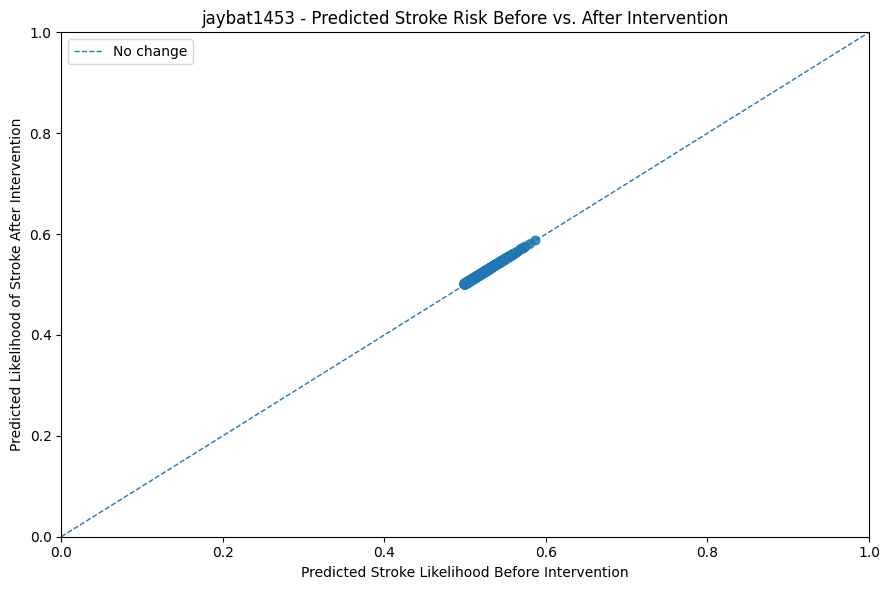

Average change in predicted likelihood: 0.0025
Patients with lower predicted likelihood: 0
Patients with higher predicted likelihood: 1500


In [7]:
plt.figure(figsize=(9, 6))
plt.scatter(
    intervention_group['Predicted Likelihood of stroke before intervention'],
    intervention_group['Predicted Likelihood of stroke after intervention'],
    alpha=0.6
)
limits = [0, 1]
plt.plot(limits, limits, linestyle='--', linewidth=1, label='No change')
plt.title(f'{student_id} - Predicted Stroke Risk Before vs. After Intervention')
plt.xlabel('Predicted Stroke Likelihood Before Intervention')
plt.ylabel('Predicted Likelihood of Stroke After Intervention')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

risk_change = (
    intervention_group['Predicted Likelihood of stroke after intervention'] -
    intervention_group['Predicted Likelihood of stroke before intervention']
)
print('Average change in predicted likelihood:', round(risk_change.mean(), 4))
print('Patients with lower predicted likelihood:', int((risk_change < 0).sum()))
print('Patients with higher predicted likelihood:', int((risk_change > 0).sum()))

In [8]:
risk_groups = intervention_group.copy()
risk_groups['Baseline Risk Quartile'] = pd.qcut(
    risk_groups['Predicted Likelihood of stroke before intervention'],
    q=4, duplicates='drop'
)
risk_summary = risk_groups.groupby('Baseline Risk Quartile', observed=False).agg(
    Patient_Count=('Predicted Likelihood of stroke before intervention', 'size'),
    Mean_Risk_Before=('Predicted Likelihood of stroke before intervention', 'mean'),
    Mean_Risk_After=('Predicted Likelihood of stroke after intervention', 'mean')
)
risk_summary['Mean Change'] = risk_summary['Mean_Risk_After'] - risk_summary['Mean_Risk_Before']
display(risk_summary)

,Patient_Count,Mean_Risk_Before,Mean_Risk_After,Mean Change
Baseline Risk Quartile,,,,
"(0.497, 0.507]",375,0.502608,0.505268,0.002660
"(0.507, 0.517]",375,0.511928,0.514494,0.002565
"(0.517, 0.531]",375,0.523067,0.525461,0.002394
"(0.531, 0.587]",375,0.543908,0.546160,0.002251
